In [376]:
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt
import copy
import os

In [377]:
# 1.
img_dir = "img/"
img_paths = os.listdir(img_dir)
img_paths.sort()
images = []

for path in img_paths:
    images.append(cv2.imread(img_dir+path))

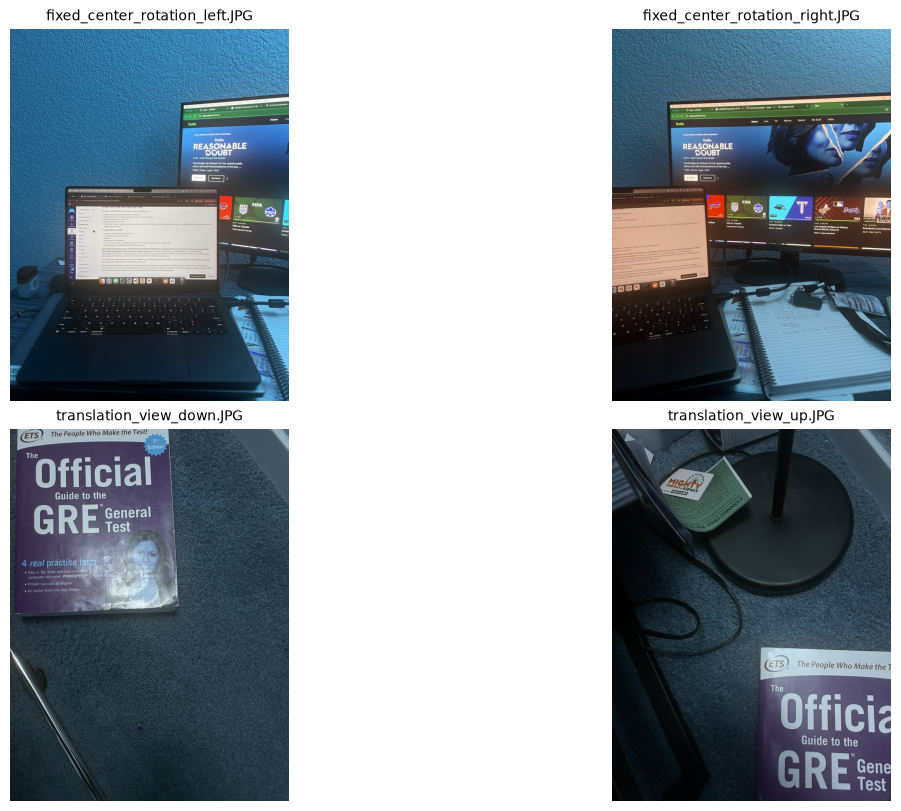

In [378]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()

for i in range(len(axes)):
    if i < 4:
        axes[i].imshow(images[i])
        axes[i].set_title(img_paths[i], fontsize=10)
        axes[i].axis('off')
    else:
        axes[i].axis('off')
        
plt.show()

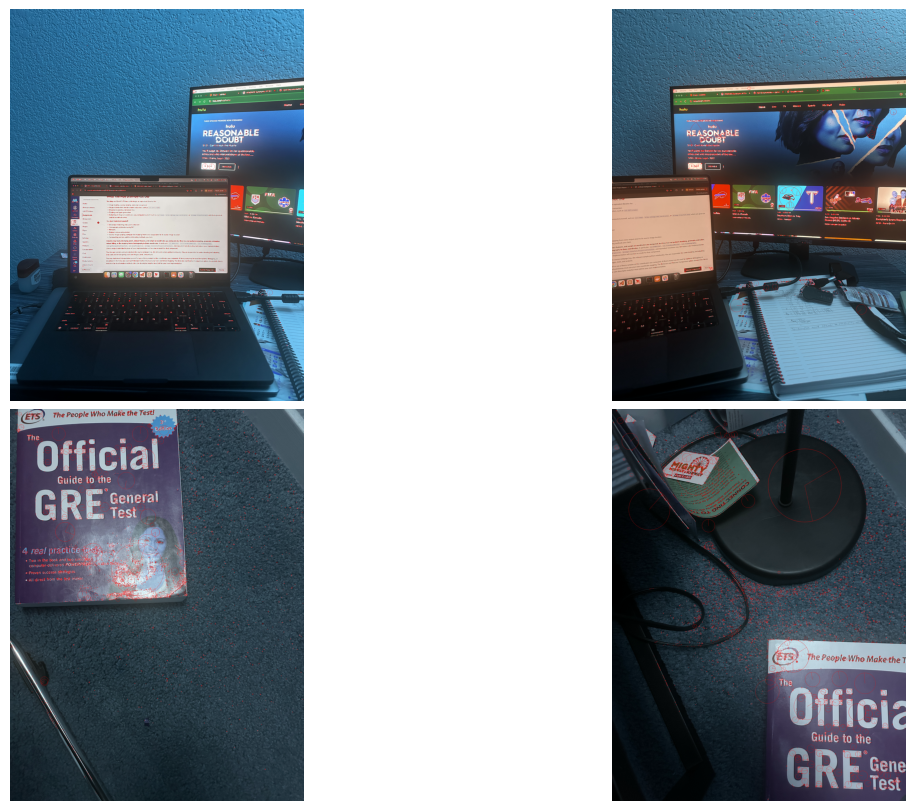

In [379]:
sift_ls = []
i = 0
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()
for img in images:

    sift = cv2.SIFT_create(nfeatures=8000)
    kp, desc = sift.detectAndCompute(img, None)
    sift_ls.append((kp,desc))

    keypoint_img = cv2.drawKeypoints(img, kp, outImage=None, color=(255,0,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    
    axes[i].imshow(keypoint_img)
    axes[i].axis('off')
    i+=1
            
plt.show()

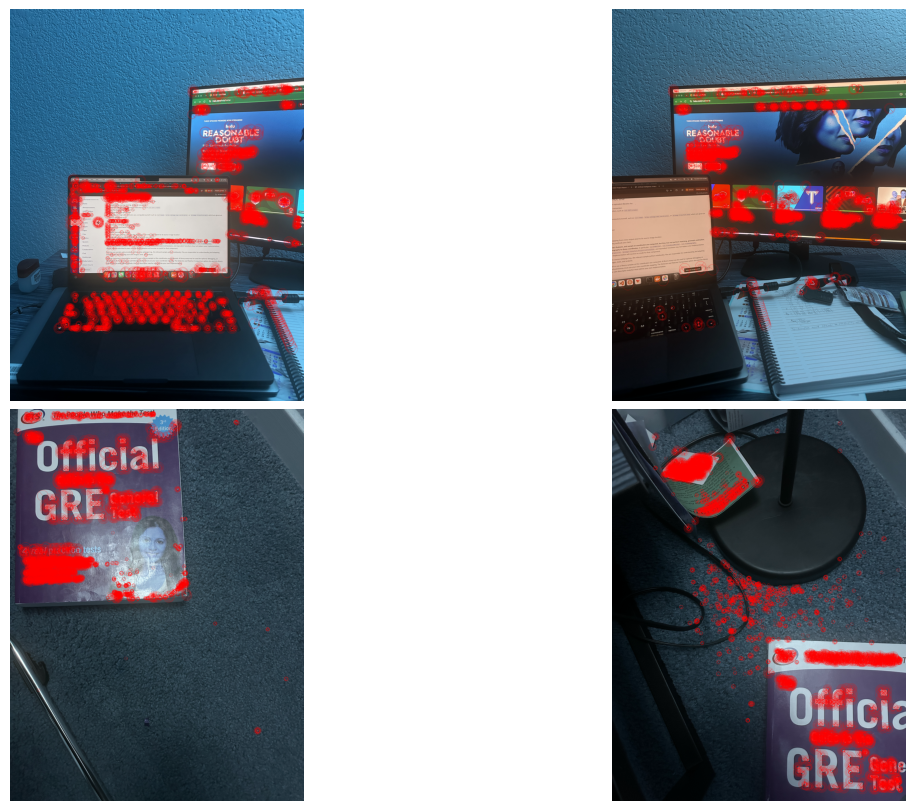

In [380]:
orb_ls = []
i = 0
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()
for img in images:

    orb = cv2.ORB_create(nfeatures=8000)
    kp, desc = orb.detectAndCompute(img, None)
    orb_ls.append((kp,desc))

    keypoint_img = cv2.drawKeypoints(img, kp, outImage=None, color=(255,0,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    
    axes[i].imshow(keypoint_img)
    axes[i].axis('off')
    i+=1
            
plt.show()

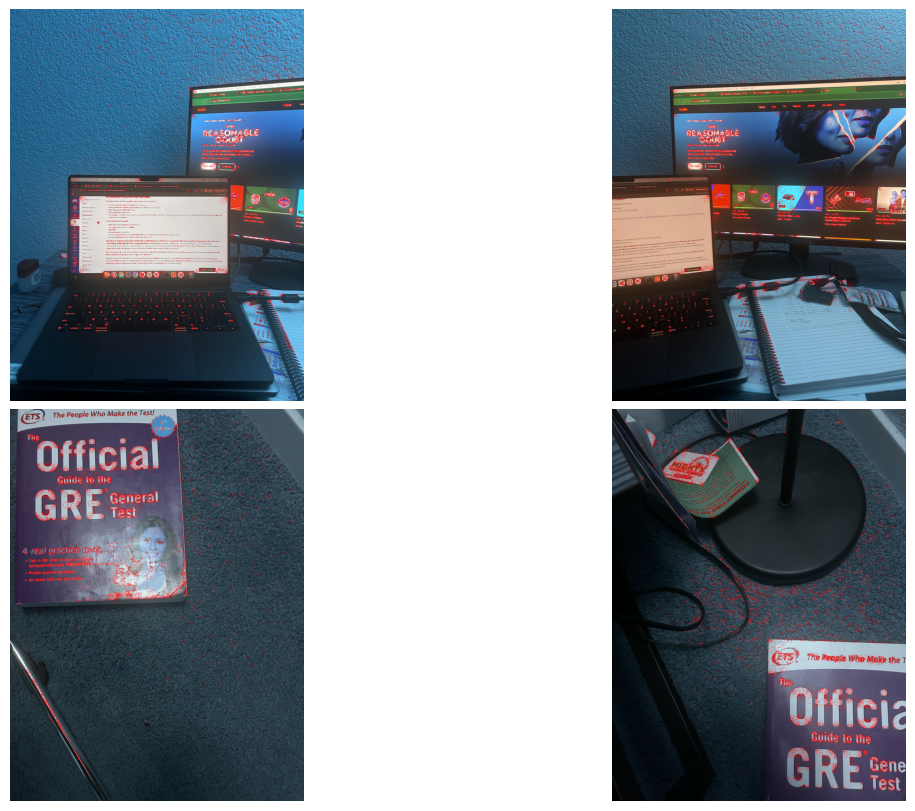

In [381]:
akaze_ls = []
i = 0
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()
for img in images:

    akaze = cv2.AKAZE_create(max_points=8000)
    kp, desc = akaze.detectAndCompute(img, None)
    akaze_ls.append((kp,desc))

    keypoint_img = cv2.drawKeypoints(img, kp, outImage=None, color=(255,0,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    
    axes[i].imshow(keypoint_img)
    axes[i].axis('off')
    i+=1
            
plt.show()

In [382]:
#2.
sift1 = sift_ls[0][1]
sift2 = sift_ls[1][1]
def descriptor_matching(desc1, desc2):
    result = []
    for i in range(len(desc1)):
        best = [np.inf, i, -1]
        second = [np.inf, i, -1]
        for j in range(len(desc2)):
            dist = np.linalg.norm(desc1[i] - desc2[j])
            if dist < best[0]:
                second = best
                best = [dist, i, j]
            elif dist < second[0]:
                second = [dist, i, j]
        result.append([best, second])
    good = [m for m, n in result if m[0] < 0.75 * n[0]]
    print(len(result), "->", len(good))
    return good

good = descriptor_matching(sift_ls[0][1], sift_ls[1][1])
good_orb = descriptor_matching(orb_ls[0][1], orb_ls[1][1])
good_akaze = descriptor_matching(akaze_ls[0][1], akaze_ls[1][1])

8000 -> 1145
8000 -> 10
8000 -> 61


In [383]:
#3. 
def find_homography(good_index, kp1, kp2):
    A = []
    for index in good_index:
        A.append([kp1[index[1]].pt[0], kp1[index[1]].pt[1], 1, 0, 0, 0, -(kp2[index[2]].pt[0]*kp1[index[1]].pt[0]), -(kp2[index[2]].pt[0]*kp1[index[1]].pt[1]), -(kp2[index[2]].pt[0])])
        A.append([0, 0, 0, kp1[index[1]].pt[0], kp1[index[1]].pt[1], 1, -(kp2[index[2]].pt[1]*kp1[index[1]].pt[0]), -(kp2[index[2]].pt[1]*kp1[index[1]].pt[1]), -(kp2[index[2]].pt[1])])

    U, S, Vt = np.linalg.svd(A)
    h = Vt[-1]

    H = h.reshape(3, 3)
    H = H / H[2,2]

    return H


In [384]:
def project(H, pts):
    ph = np.column_stack([pts, np.ones(len(pts))]) @ H.T
    return ph[:, :2] / ph[:, 2:3]

def mean_err(H, src, dst):
    return np.linalg.norm(project(H, src) - dst, axis=1).mean()
H_true = np.array([[ 0.9, 0.1, 40.], [-0.05, 1.1, 20.],
[ 3e-4, -2e-4, 1. ]])
src = np.array([[50., 40.], [600., 70.], [560., 430.], [80., 400.]])
dst = project(H_true, src) 

def convert_to_keypoints(pts):
    a = []
    for p in pts:
        a.append(cv2.KeyPoint(p[0], p[1], 0))
    return a
src_keypoints = convert_to_keypoints(src)
dst_keypoints = convert_to_keypoints(dst)
temp_good = [[0, 0, 0], [0,1,1], [0,2,2], [0,3,3]]
H = find_homography(temp_good, src_keypoints, dst_keypoints)
print(mean_err(H, src, dst)) 

6.800361286426497e-06


In [385]:
src = np.array([[55., 430.], [643., 76.], [534., 346.], [23., 463.], [264., 46.], [646., 74.], [133., 46.], [246., 57.]])
dst = project(H_true, src) 
src_keypoints = convert_to_keypoints(src)
dst_keypoints = convert_to_keypoints(dst)
temp_good = [[0, 0, 0], [0,1,1], [0,2,2], [0,3,3], [0, 4, 4], [0,5,5], [0,6,6], [0,7,7]]
H = find_homography(temp_good, src_keypoints, dst_keypoints)
print(mean_err(H, src, dst)) 

1.1534873013502798e-05


In [386]:
#4. 
def reprojection_error(src, dst, H):
    src_h = np.column_stack([src, np.ones(len(src))]) # (N,3), one point per ROW
    pred_h = src_h @ H.T # transpose: points are rows
    pred = pred_h[:, :2] / pred_h[:, 2:3] # the dividepred_h[:, 2:3]
    err = np.linalg.norm(pred - dst, axis=1) # (N,) pixel distances
    return err

import random
def ransac_adaptive(good_index, kp1, kp2):
    
    
    src_array = np.array([kp1[m[1]].pt for m in good_index])
    dst_array = np.array([kp2[m[2]].pt for m in good_index])

    p = 0.99
    w = 0.0
    s = 4
    l = len(src_array)
    N = 1000
    
    final = [0, []]
    for i in range(N):
        random_nums = random.sample(range(0, len(good_index)), 4)
        sample_good_index = [good_index[i] for i in random_nums]
        H = find_homography(sample_good_index, kp1, kp2)
        if np.linalg.matrix_rank(H) != 3:
            i-=1
            continue
        err = reprojection_error(src_array, dst_array, H)
        inliers = err < 3.0 # threshold in working-image pixels
        if inliers.sum() > final[0]:
            final = [inliers.sum(), inliers]
        
        if inliers.sum()/l > w: # Confidence-Based RANSAC Stopping
            w = inliers.sum()/l
            N = int(np.ceil(np.log(1-p)/np.log(1-w**s)))
    
    print(f"N: {N}")
    
    final_good_index = [good_index[i] for i in range(len(final[1])) if final[1][i]]
    H = find_homography(final_good_index, kp1, kp2)
    err = reprojection_error(src_array, dst_array, H)
    inliers = err < 3.0 # threshold in working-image pixels
    print(inliers.sum(), len(inliers), err[inliers].mean())
    return H

def ransac(good_index, kp1, kp2, threshold):
    
    
    src_array = np.array([kp1[m[1]].pt for m in good_index])
    dst_array = np.array([kp2[m[2]].pt for m in good_index])

    final = [0, []]
    for i in range(1000):
        random_nums = random.sample(range(0, len(good_index)), 4)
        sample_good_index = [good_index[i] for i in random_nums]
        H = find_homography(sample_good_index, kp1, kp2)
        if np.linalg.matrix_rank(H) != 3:
            i-=1
            continue
        err = reprojection_error(src_array, dst_array, H)
        inliers = err < threshold # threshold in working-image pixels
        if inliers.sum() > final[0]:
            final = [inliers.sum(), inliers]
        
    final_good_index = [good_index[i] for i in range(len(final[1])) if final[1][i]]
    H = find_homography(final_good_index, kp1, kp2)
    err = reprojection_error(src_array, dst_array, H)
    inliers = err < threshold # threshold in working-image pixels
    print(inliers.sum(), len(inliers), err[inliers].mean())
    return inliers.sum(), err[inliers].mean() 


260 1145 0.5237546124015932
374 1145 0.9292550432212853
397 1145 0.8436872114603845
421 1145 1.0142877964307915
443 1145 1.1686656099548012
443 1145 1.1615167880924815
443 1145 1.1637838193208496
443 1145 1.179755938189652
443 1145 1.1632880991364394
443 1145 1.1632880991364394
444 1145 1.2178231603514822
444 1145 1.2178231603514822
445 1145 1.2435820221635585
445 1145 1.2270019341923493
445 1145 1.5240240917722918
445 1145 1.5240240917722918
445 1145 1.2435820221635585
445 1145 1.2435820221635585
445 1145 1.39439234697362
445 1145 1.5240240917722918


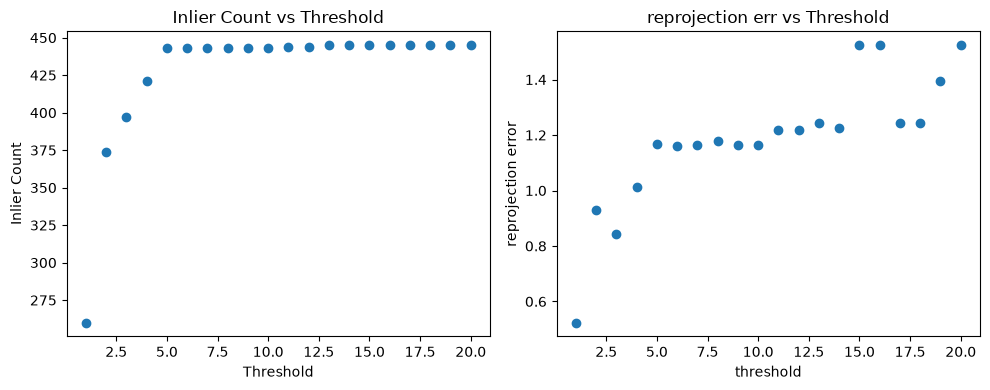

In [387]:
# RANSAC Parameter Analysis
inlier_count_ls = []
err_ls = []
thresholds = range(1, 21)
for i in thresholds:
    inlier_count, err = ransac(good, sift_ls[0][0], sift_ls[1][0], i)
    inlier_count_ls.append(inlier_count)
    err_ls.append(err)
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# 3. Plot the first scatter plot on 'ax1' (left side)
ax1.scatter(thresholds, inlier_count_ls)
ax1.set_title('Inlier Count vs Threshold')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('Inlier Count')

# 4. Plot the second scatter plot on 'ax2' (right side)
ax2.scatter(thresholds, err_ls)
ax2.set_title('reprojection err vs Threshold')
ax2.set_xlabel('threshold')
ax2.set_ylabel('reprojection error')

# 5. Clean up layout and display
plt.tight_layout() # Prevents labels from overlapping
plt.show()

In [389]:
homography = ransac_adaptive(good, sift_ls[0][0], sift_ls[1][0])
homography_orb = ransac_adaptive(good_orb, orb_ls[0][0], orb_ls[1][0])
homography_akaze = ransac_adaptive(good_akaze, akaze_ls[0][0], akaze_ls[1][0])

N: 398
406 1145 0.9426909289838268
N: 72
6 10 0.9525341060914947
N: 32
37 61 0.818765725743684


In [390]:
def view_warped_image(images_to_warp, H, bilinear: bool):
    image_to_reference = [H, np.eye(3)]
    source_corners = []
    reference_corners = []
    for image, H in zip(images, image_to_reference):
        h, w = image.shape[:2]
        corners = np.array([[0., 0.], [w - 1., 0.],
                            [w - 1., h - 1.], [0., h - 1.]])
        corners_h = np.column_stack([corners, np.ones(4)])
        moved_h = corners_h @ H.T
        # A finite corner box is useful only when the image does not cross infinity.
        denom = moved_h[:, 2]
        assert np.all(denom > 1e-10) or np.all(denom < -1e-10)
        moved = moved_h[:, :2] / denom[:, None]
        source_corners.append(corners)
        reference_corners.append(moved)


    all_corners = np.vstack(reference_corners)
    x_min, y_min = np.floor(all_corners.min(axis=0)).astype(int)
    x_max, y_max = np.ceil(all_corners.max(axis=0)).astype(int)
    canvas_w = int(x_max - x_min + 1)
    canvas_h = int(y_max - y_min + 1)

    T = np.array([[1., 0., -x_min], [0., 1., -y_min], [0., 0., 1.]])
    image_to_canvas = [T @ H for H in image_to_reference]

    canvas_y, canvas_x = np.indices((canvas_h, canvas_w), dtype=float)
    canvas_points = np.column_stack([canvas_x.ravel(), canvas_y.ravel(),
                                    np.ones(canvas_h * canvas_w)])
    source_maps = []
    valid_masks = []
    for image, G in zip(images_to_warp, image_to_canvas):
        source_h = canvas_points @ np.linalg.inv(G).T
        denominator = source_h[:, 2]
        finite = np.isfinite(source_h).all(axis=1) & (np.abs(denominator) > 1e-10)
        source_xy = np.full((len(canvas_points), 2), np.nan)
        source_xy[finite] = source_h[finite, :2] / denominator[finite, None]
        map_x = source_xy[:, 0].reshape(canvas_h, canvas_w)
        map_y = source_xy[:, 1].reshape(canvas_h, canvas_w)
        h, w = image.shape[:2]
        # This demo samples only within the rectangle of source pixel centers.
        valid = (np.isfinite(map_x) & np.isfinite(map_y) &
                (map_x >= 0) & (map_x <= w - 1) &
                (map_y >= 0) & (map_y <= h - 1))
        source_maps.append((map_x, map_y))
        valid_masks.append(valid)

    from scipy.ndimage import map_coordinates

    warped_images = []
    for image, (map_x, map_y), valid in zip(images_to_warp, source_maps, valid_masks):
        safe_x = np.where(valid, map_x, 0)
        safe_y = np.where(valid, map_y, 0)
        warped = np.stack([
            map_coordinates(image[..., channel], [safe_y, safe_x],
                            order=1 if bilinear else 0, mode="constant", cval=0)
            for channel in range(3)
        ], axis=-1)
        warped[~valid] = 0
        warped_images.append(warped)

    overwrite_1 = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)
    for warped, valid in zip(warped_images[::-1], valid_masks[::-1]):
        overwrite_1[valid] = warped[valid]

    plt.figure(figsize=(9, 6))  
    plt.imshow(overwrite_1)
    # plt.title("Overwrite: A first, then B")
    plt.axis("off"); plt.tight_layout(); plt.show()

SIFT Warp


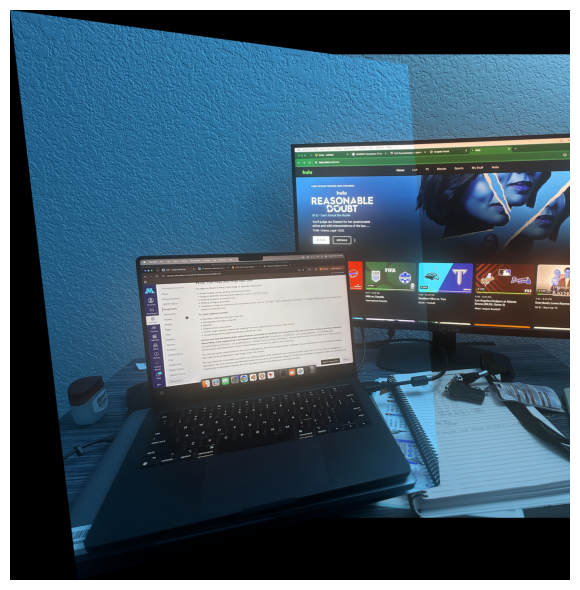

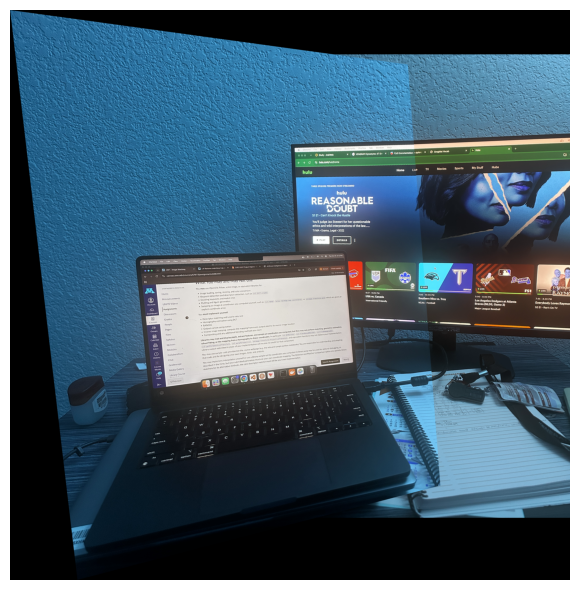

Orb Warp


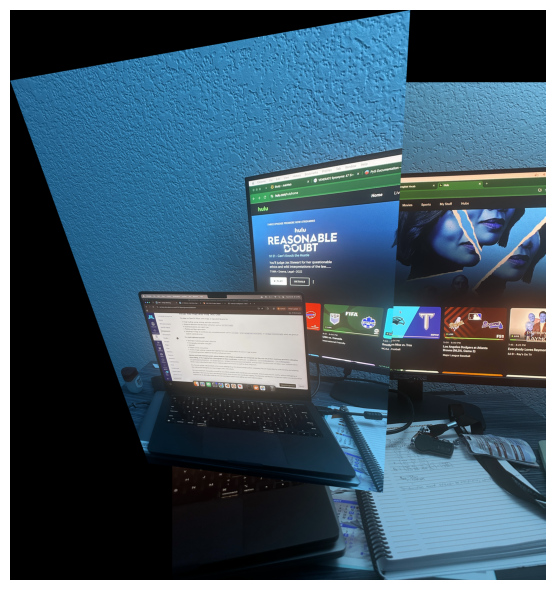

AKAZE Warp


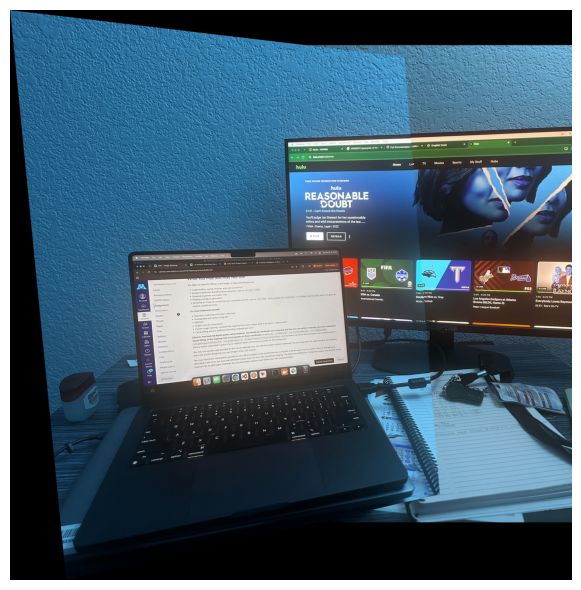

In [391]:
print("SIFT Warp")
view_warped_image(images[:2], homography, True)
view_warped_image(images[:2], homography, False)
print("Orb Warp")
view_warped_image(images[:2], homography_orb, True)
print("AKAZE Warp")
view_warped_image(images[:2], homography_akaze, True)

In [392]:
good2 = descriptor_matching(sift_ls[2][1], sift_ls[3][1])
homography2 = ransac_adaptive(good2, sift_ls[2][0], sift_ls[3][0])

8000 -> 497
81 497 0.5662429025145952


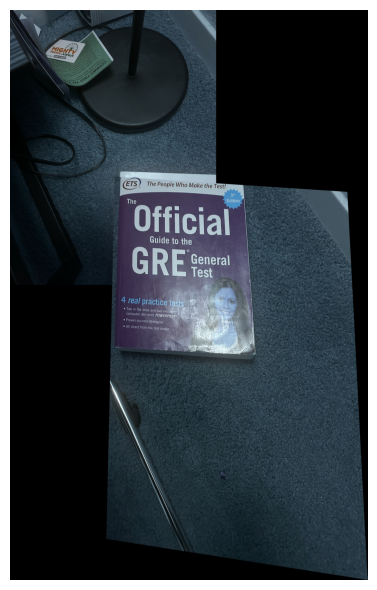

In [396]:
view_warped_image(images[2:], homography2, True)